# 07 - Multimodal Architecture: One Shared Space for More Than Text

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Make sure we get outputs from a probabilitistic model each time (for reproducibility)
np.random.seed(1515)

## The Lead up To Multimodality

`ai_primer`'s glossary defines a Prompt as "text, an image, or a combination" without ever explaining the combination part. If we wanted to create a really strong scouting agent, there's a good chance we need both written notes and actual game footage.

In this notebook, we cover how we can leverage Transformers in a **multimodal** context, meaning it can take in more than just text inputs. 

## Everything Becomes a Vector in the Same Space

In our previous notebooks in this unit, `self_attention` never once checked what kind of thing a vector represented. It only ever computed dot products between rows of a matrix. A token's embedding earned its place in that matrix purely by having the right shape.

If you can turn an image into a sequence of vectors of that same width, self-attention will relate an image vector to a text vector exactly the way `02-attention-mechanism.ipynb` related `it` to `robot`. This is not because the mechanism was extended to "understand pictures," but because it never distinguished modalities to begin with. The only new problem is upstream of attention: how does an image become a sequence of same-shaped vectors in the first place?

## Patch Embeddings: Tokenizing an Image

`cv_primer` represents a grayscale image as a grid of pixels ($H \times W$). A **patch embedding** cuts that grid into small, fixed-size squares, flattens each square into a single long vector of raw pixel values, and multiplies it through one learned projection matrix. This gives us a matrix-vector product, or `linear_algebra_primer/02-matrices-and-transformations.ipynb`'s row-indexing-adjacent operation. The result is a `d_model`-dimensional vector. 

Do that for every patch and an image becomes a *sequence* of vectors, structurally identical to `01-tokenization-and-embeddings.ipynb`'s sequence of token embeddings. This is literally what "tokenizing" an image means in a Vision Transformer.

See below for a tiny 8x8 toy image, split into four non-overlapping 4x4 patches, each flattened to 16 raw pixel values and projected down to a 4-dim vector. It's the same `d_model = 4` every notebook in this primer has used.

In [2]:
image_size = 8
patch_size = 4

toy_image = np.full((image_size, image_size), 0.1)
toy_image[4:8, 0:4] = 0.9   # a bright blob, entirely inside the bottom-left patch

patches, patch_names = [], []
i = 0
for row_block in range(image_size // patch_size):
    for col_block in range(image_size // patch_size):
        patch = toy_image[row_block*patch_size:(row_block+1)*patch_size,
                           col_block*patch_size:(col_block+1)*patch_size]
        patches.append(patch.flatten())
        patch_names.append(f"P{i}")
        i += 1
patches = np.array(patches)
print(f"Patches shape: {patches.shape}  ({len(patch_names)} patches, {patch_size*patch_size} raw pixels each)")

d_model = 4
W_patch = np.random.randn(patch_size * patch_size, d_model) * 0.3
patch_embeddings_mechanical = patches @ W_patch
print(f"Patch embeddings shape: {patch_embeddings_mechanical.shape}  (compare to a token embedding sequence)")
print(patch_embeddings_mechanical.round(3))

Patches shape: (4, 16)  (4 patches, 16 raw pixels each)
Patch embeddings shape: (4, 4)  (compare to a token embedding sequence)
[[-0.087  0.065  0.227  0.019]
 [-0.087  0.065  0.227  0.019]
 [-0.779  0.587  2.042  0.174]
 [-0.087  0.065  0.227  0.019]]


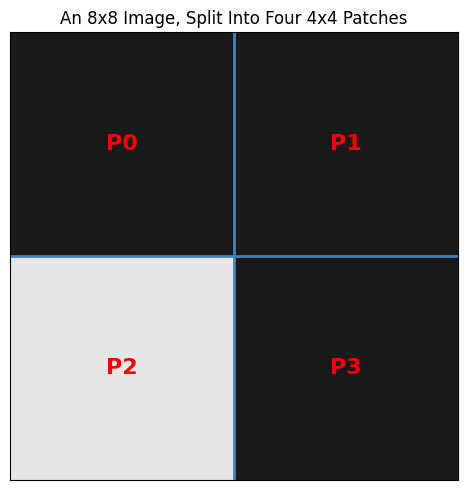

In [3]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(toy_image, cmap='gray', vmin=0, vmax=1)
for k in range(1, image_size // patch_size):
    ax.axhline(k * patch_size - 0.5, color='steelblue', linewidth=2)
    ax.axvline(k * patch_size - 0.5, color='steelblue', linewidth=2)

i = 0
for row_block in range(image_size // patch_size):
    for col_block in range(image_size // patch_size):
        cy = row_block * patch_size + patch_size / 2 - 0.5
        cx = col_block * patch_size + patch_size / 2 - 0.5
        ax.text(cx, cy, patch_names[i], color='red', fontsize=16, ha='center', va='center', fontweight='bold')
        i += 1

ax.set_title('An 8x8 Image, Split Into Four 4x4 Patches')
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

The bright blob sits entirely inside P2, and P2's projected embedding is the one that visibly differs from the other three (which are identical). A real, trained patch-projection matrix would learn to map a patch that looks like "part of a robot mid-climb" into an embedding that lands near `robot` and `climbed` in the model's shared embedding space. It's the same way `01`'s BPE merges learned to land `climb` near other climbing-related tokens, purely from what co-occurs with what. We don't have that training here, so (like `02`'s coreference example) the next section hand-designs what a *learned* patch embedding would need to look like, so the resulting cross-modal attention is something you can verify, not just take on faith.

## Contrast with Convolution

`cv_primer/04-convolution.ipynb` built translation-invariant feature detection a completely different way: slide one small kernel across the *entire* image, reusing the same learned weights at every position, and stack many convolutional layers to gradually grow how much of the image any one output value depends on (its receptive field). 

Patch embedding does neither of those things. Instead, it cuts the image into non-overlapping pieces exactly once, projects each piece independently with no sliding or weight-sharing across positions, and then hands the whole thing to self-attention to relate far-apart patches in a single step. It is the same all-pairs-at-once computation `03` used to argue attention beat sequential RNNs.

Neither approach is architecturally "better" in the abstract. A CNN's weight-sharing bakes in a strong, free assumption (nearby pixels tend to relate to each other) that helps it learn from comparatively little data. Patch embedding plus attention bakes in no such assumption; the model has to learn any spatial relationships, nearby or distant, entirely from data, which costs more data and compute to get right but places no ceiling on what kind of relationship it can eventually learn.

## One Sequence, One Attention Computation

Reuse `02`'s exact coreference sentence ("the robot climbed because it was fast") and concatenate four patch tokens onto the end of it. `P2` is hand-designed to carry the same distinctive marker `02` gave `robot` (dim 3), representing what a trained model would have learned for "a patch showing part of a robot mid-climb." `P0`, `P1`, `P3` stay near-zero everywhere, standing in for background patches with nothing distinctive in them.

In [4]:
def softmax_rows(z):
    z = z - z.max(axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=1, keepdims=True)

def self_attention(x):
    d_k = x.shape[1]
    scores = (x @ x.T) / np.sqrt(d_k)
    weights = softmax_rows(scores)
    return weights, weights @ x

text_labels = ["the", "robot", "climbed", "because", "it", "was", "fast"]
text_embeddings = np.array([
    [0.3, 0.0, 0.0, 0.0],
    [3.0, 0.3, 0.0, 1.5],   # robot - carries the distinctive marker, same as 02
    [0.0, 0.0, 3.0, 0.4],
    [0.0, 0.3, 0.0, 0.0],
    [2.8, 0.2, 0.0, 0.0],   # it - no marker of its own, same as 02
    [0.0, 0.0, 0.3, 0.0],
    [0.0, 0.0, 2.8, 0.3],
])

patch_labels = ["P0", "P1", "P2", "P3"]
patch_embeddings = np.array([
    [0.1, 0.05, 0.1, 0.0],
    [0.05, 0.1, 0.05, 0.0],
    [2.5, 0.1, 0.0, 1.3],   # P2 - hand-designed to share robot's distinctive marker
    [0.1, 0.0, 0.05, 0.05],
])

labels = text_labels + patch_labels
combined = np.vstack([text_embeddings, patch_embeddings])
weights, output = self_attention(combined)

it_idx = labels.index("it")
print("'it' attention weights, highest three:")
for i in np.argsort(weights[it_idx])[::-1][:3]:
    print(f"  {labels[i]:8s} {weights[it_idx, i]:.3f}")

'it' attention weights, highest three:
  robot    0.423
  it       0.316
  P2       0.206


In `02`, with text alone, `it` put about 55% of its attention on `robot` because that was the only other token carrying its distinctive marker. Add an image patch carrying that *same* marker to the sequence, and `it`'s attention splits three ways instead of two: itself, the word `robot`, and now the patch `P2` as well. All three are clearly separated from every other token or patch, which sit near the ~0.006-0.01 background level a completely irrelevant candidate gets. Nothing about the mechanism changed. `it` simply had one more relevant thing to look at, and attention found it regardless of whether that thing was a word or a picture.

In [5]:
print("'it' original embedding:  ", text_embeddings[it_idx].round(2))
print("'it' attention output:    ", output[it_idx].round(2))

'it' original embedding:   [2.8 0.2 0.  0. ]
'it' attention output:     [2.67 0.21 0.04 0.91]


Look at the last number again, same test `02` ran: `it`'s own embedding had a `0` there, and its attention output now carries roughly `0.9`. That is pulled in from *both* `robot`'s Value vector and `P2`'s Value vector, blended by their respective attention weights. That number didn't come from text alone or from the image alone. It came from both, added together by the exact same weighted-average step every notebook in this primer has used.

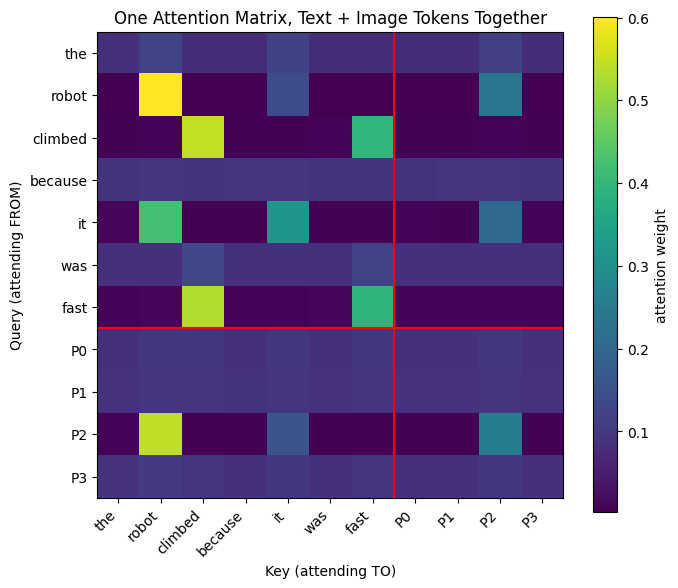

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(weights, cmap='viridis')
ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticklabels(labels)
ax.axvline(6.5, color='red', linewidth=1.5)
ax.axhline(6.5, color='red', linewidth=1.5)
ax.set_xlabel('Key (attending TO)')
ax.set_ylabel('Query (attending FROM)')
ax.set_title('One Attention Matrix, Text + Image Tokens Together')
plt.colorbar(im, label='attention weight')
plt.tight_layout()
plt.show()

The red lines just mark where text tokens end and patch tokens begin; the attention matrix itself doesn't know or care that boundary exists. A bright cell can show up on either side of it, for either kind of query, which is what "multimodal" architecturally means.

## Where This Actually Shows Up

If you've ever pasted a photo into ChatGPT or Claude and asked a question about it, how does it work to give you a text or image (or both) answer back? 

 The image gets patch-embedded into the same space your text prompt's tokens live in, and one Transformer attends over all of it together.

Another example is the CLIP-style model like the one in the Resources. It is built from two encoders, one for text and one for images, trained so that matching image-caption pairs land close together in the shared space. Nothing in it generates text; generating an answer about an image needs a decoder on top, which is what the chat models above add.

## Try It Yourself

Move the bright blob to a different quadrant of `toy_image` (e.g. top-right: `toy_image[0:4, 4:8] = 0.9`), rerun the patchify-and-project cell and its visualization, and confirm which patch now has the visibly different projected embedding. Then, in the hand-designed cross-modal section, move the distinctive marker from `P2` to whichever patch you just identified, rerun the self-attention cell, and verify `it` now attends most strongly to *that* patch instead of `P2`. One sentence: what had to change for the result to hold, and what didn't?

In [7]:
# TODO: move the blob to a different quadrant of toy_image, rerun the patchify +
# projection + visualization cells, identify the new distinctive patch, move the
# hand-designed marker to that patch in patch_embeddings, and confirm 'it' still
# finds it after self-attention


## Resources

- Dosovitskiy, A. et al. (2020). "An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale" (the Vision Transformer / ViT paper). The paper behind the patch-embedding mechanism built above (paper).
- Radford, A. et al. (2021). "Learning Transferable Visual Models From Natural Language Supervision" (the CLIP paper). A real, trained shared text/image embedding space, learned by pulling matching image-caption pairs together and pushing mismatched pairs apart (paper).
- [Hugging Face: Vision Transformer (ViT)](https://huggingface.co/docs/transformers/en/model_doc/vit) - documentation for a real, loadable ViT model, including its patch size and embedding dimension as actual config values instead of this notebook's toy 4x4/4-dim stand-ins (reference).